# Multi-Domain Digital Signal Processing Project

**Team members:**
- Ahmed Mohamed Ramadan — 212300037
- Omar Ashraf Abdelhady — 212231416
- Abdullah Hussein Sayed — 212300261
- Youssef Nasser Sayed Ahmed — 212300554

## Project roadmap

| Part | Main question | Output |
|---|---|---|
| 1. Manual DTFT | Which frequencies exist in a signal? | Magnitude and phase plots |
| 2. Convolution | How does a digital system process a signal? | Filtered signal and convolution comparison |
| 3. Audio analysis | How can we find unwanted hum? | Clean/noisy waveforms and spectra |
| 4. Notch filter | How can we remove one unwanted frequency? | Filtered audio and filter response |
| 5. Image Fourier filtering | What do low and high spatial frequencies represent? | Blurred and edge images |
| 6. Image restoration | How can periodic image noise be removed? | Restored image, MSE, and PSNR |

## Shared setup
The next cell imports the libraries and defines reusable helpers for loading audio, loading an image, calculating PSNR, and calculating an audio spectrum.

In [15]:
# Libraries used throughout the six phases
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
import cv2
from IPython.display import Audio, display

# Input filenames.
AUDIO_FILE = 'audio.wav'
IMAGE_FILE = 'image.png'
np.random.seed(0)

# Load real audio when available
def load_audio(path=AUDIO_FILE):
    """Load mono audio and scale it to [-1, 1]."""
    if os.path.exists(path):
        fs, x = wavfile.read(path)
        x = x.astype(np.float64)
        if x.ndim > 1:
            x = x.mean(axis=1)
    else:
        print('audio.wav not found: using synthetic audio')
        fs = 8000
        t = np.arange(3 * fs) / fs
        x = (np.sin(2*np.pi*150*t) + 0.6*np.sin(2*np.pi*300*t) + 0.4*np.sin(2*np.pi*900*t)) * (0.6 + 0.4*np.sin(2*np.pi*3*t))
    return fs, x / np.max(np.abs(x))

# Load the real image in grayscale and resize it for fast 2D Fourier processing.
def load_image(path=IMAGE_FILE, size=256):
    """Load a grayscale float image with values from 0 to 255."""
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE) if os.path.exists(path) else None
    if img is None:
        print('image.png not found: using a synthetic test image')
        yy, xx = np.mgrid[:size, :size]
        img = 40 + 0.4*xx + 0.2*yy
        img[60:130, 50:140] = 220
        img[((yy-170)**2 + (xx-170)**2) < 40**2] = 120
        img = np.clip(img, 0, 255)
    else:
        img = cv2.resize(img, (size, size))
    return img.astype(np.float64)

# Measure image error (MSE) and reconstruction quality (PSNR).
def psnr(reference, test):
    test = np.clip(test, 0, 255)
    mse = np.mean((reference - test)**2)
    return mse, np.inf if mse == 0 else 10*np.log10(255**2 / mse)

# Return the positive frequencies and their amplitudes for a real audio signal.
def amp_spectrum(sig, fs):
    return np.fft.rfftfreq(len(sig), 1/fs), 2*np.abs(np.fft.rfft(sig))/len(sig)


## Part 1 — Mathematical signal and manual DTFT

**Goal:** Create a signal containing two sine waves and random noise, then discover its frequencies using the DTFT definition.

**Idea in simple words:** The time plot shows how a signal changes sample by sample, but it does not clearly reveal which frequencies created it. The DTFT tests many possible angular frequencies. A large DTFT magnitude means that frequency is strongly present.

$$X(\omega)=\sum_{n=0}^{N-1}x[n]e^{-j\omega n}$$

The project requires this calculation to be written manually, so the code uses one loop over frequencies and another loop over samples.

**How to read the output:**
- The first plot is the noisy signal in time.
- Peaks in the magnitude plot reveal the two sine-wave frequencies.
- The phase plot describes their phase shifts; it becomes unstable where magnitude is almost zero.
- Red dashed lines mark the frequencies we expect to find.

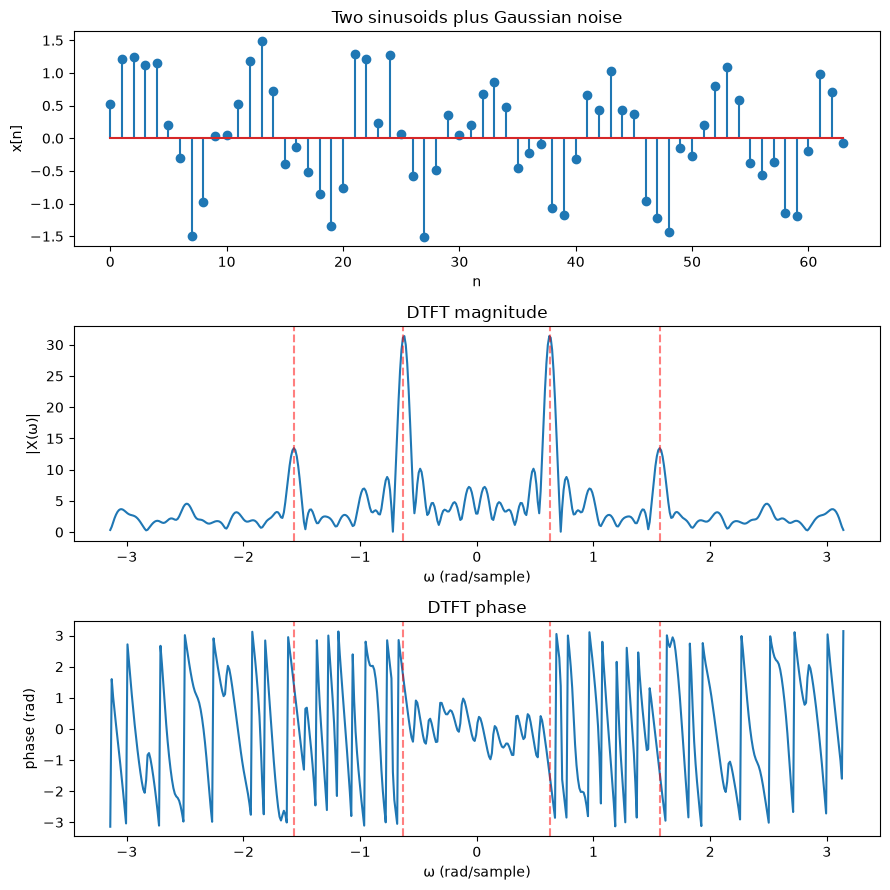

Manual DTFT matches FFT samples: True


In [16]:
# 1) Build a short signal from two sine waves and Gaussian noise.
N = 64
n = np.arange(N)
f1, f2 = 0.10, 0.25
x_math = np.sin(2*np.pi*f1*n) + 0.5*np.sin(2*np.pi*f2*n) + 0.3*np.random.randn(N)

# 2) Evaluate the DTFT manually at K angular-frequency points.
K = 512
w = np.linspace(-np.pi, np.pi, K)
X = np.zeros(K, dtype=complex)
for k in range(K):
    for i in range(N):
        X[k] += x_math[i] * np.exp(-1j*w[k]*i)


# 3) Plot the time signal, DTFT magnitude, and DTFT phase.
fig, ax = plt.subplots(3, 1, figsize=(9, 9))
ax[0].stem(n, x_math); ax[0].set(title='Two sinusoids plus Gaussian noise', xlabel='n', ylabel='x[n]')
ax[1].plot(w, np.abs(X)); ax[1].set(title='DTFT magnitude', xlabel='ω (rad/sample)', ylabel='|X(ω)|')
ax[2].plot(w, np.angle(X)); ax[2].set(title='DTFT phase', xlabel='ω (rad/sample)', ylabel='phase (rad)')
for a in ax[1:]:
    for f0 in (f1, f2):
        a.axvline(2*np.pi*f0, color='r', ls='--', alpha=.5); a.axvline(-2*np.pi*f0, color='r', ls='--', alpha=.5)
plt.tight_layout(); plt.show()

# 4) Confirm the manual DTFT agrees with the FFT at FFT-bin frequencies.
wk = 2*np.pi*np.arange(N)/N
Xk = np.array([sum(x_math[i]*np.exp(-1j*wk[k]*i) for i in range(N)) for k in range(N)])
print('Manual DTFT matches FFT samples:', np.allclose(Xk, np.fft.fft(x_math)))

### Part 1 result

The magnitude peaks appear near $\pm2\pi f_1$ and $\pm2\pi f_2$, so the DTFT correctly identifies both sine waves. Random noise appears as a low background across many frequencies. The peaks have width instead of being perfect lines because only 64 samples are used. The final `True` check confirms that the manual calculation agrees with NumPy's FFT at the FFT frequency samples.

## Part 2 — Convolution and a difference equation

**Goal:** Smooth a noisy signal with a moving-average filter, prove two convolution methods agree, and implement a simple system with feedback.

**Idea in simple words:** Convolution combines an input signal with a filter's impulse response. Here, averaging five neighbouring samples reduces rapid noise changes. The same calculation can be performed by multiplying FFTs, but both signals must be zero-padded to length $N+M-1$ to prevent circular wrap-around.

The difference equation is $y[n]=x[n]+0.8y[n-1]$. The previous output is fed back into the new output. Since $|0.8|<1$, the response decays and the system is stable.

**How to read the output:**
- The direct and zero-padded FFT convolution curves should overlap.
- The error plot shows what goes wrong without enough padding.
- The final plot compares the noisy input with the smoother difference-equation output.

Linear convolution equals zero-padded FFT: True
Maximum circular-convolution error: 0.8371705824072077
Impulse response equals a^n: True


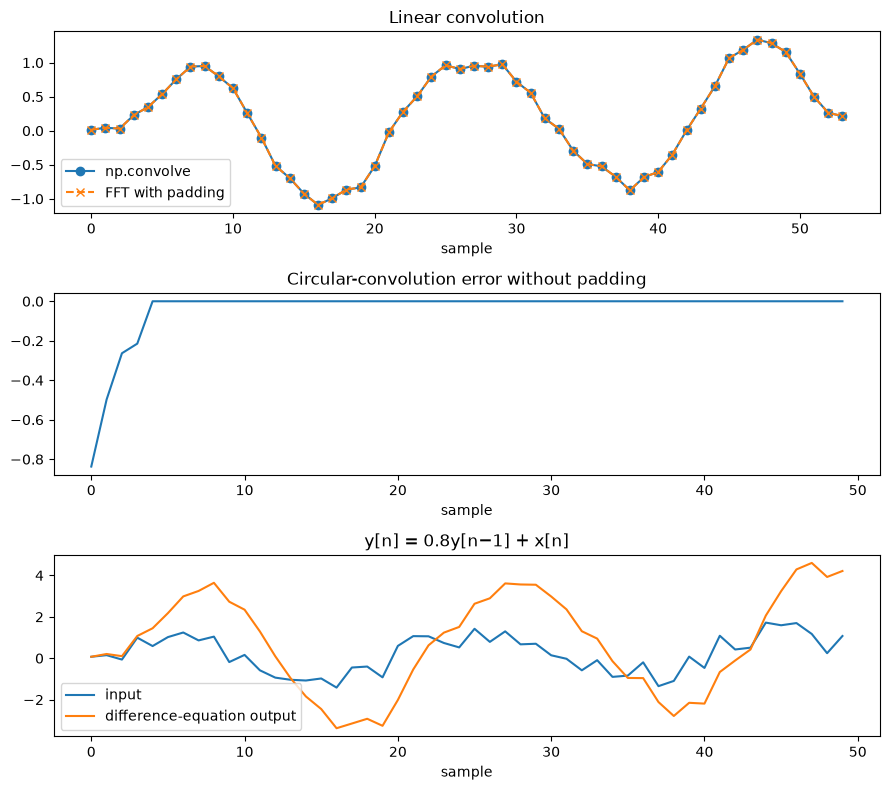

In [17]:
# 1) Create another noisy sine wave for the filtering experiment.
N2 = 50; n2 = np.arange(N2)
x2 = np.sin(2*np.pi*.05*n2) + .4*np.random.randn(N2)

# 2) A five-sample moving average: every output averages nearby inputs.
h = np.ones(5)/5
y_conv = np.convolve(x2, h)

# 3) FFT multiplication with length N+M-1 gives linear convolution.
L = len(x2) + len(h) - 1
y_fft = np.real(np.fft.ifft(np.fft.fft(x2, L)*np.fft.fft(h, L)))
# This version is intentionally not padded; it demonstrates wrap-around.
y_circ = np.real(np.fft.ifft(np.fft.fft(x2)*np.fft.fft(h, len(x2))))
print('Linear convolution equals zero-padded FFT:', np.allclose(y_conv, y_fft))
print('Maximum circular-convolution error:', np.max(np.abs(y_conv[:N2] - y_circ)))


# 4) Implement y[n] = x[n] + a*y[n-1] directly with a loop.
def first_order(x, a):
    y = np.zeros(len(x))
    for i in range(len(x)):
        y[i] = x[i] + (a*y[i-1] if i else 0)
    return y


# 5) Use a stable feedback value and test the impulse response.
a = .8
impulse = np.zeros(30); impulse[0] = 1
h_diff = first_order(impulse, a)
print('Impulse response equals a^n:', np.allclose(h_diff, a**np.arange(30)))

# 6) Compare the methods and display the first-order system output.
fig, ax = plt.subplots(3, 1, figsize=(9, 8))
ax[0].plot(y_conv, 'o-', label='np.convolve'); ax[0].plot(y_fft, 'x--', label='FFT with padding'); ax[0].legend(); ax[0].set_title('Linear convolution')
ax[1].plot(y_conv[:N2]-y_circ); ax[1].set_title('Circular-convolution error without padding')
ax[2].plot(x2, label='input'); ax[2].plot(first_order(x2, a), label='difference-equation output'); ax[2].legend(); ax[2].set_title('y[n] = 0.8y[n−1] + x[n]')
for p in ax: p.set_xlabel('sample')
plt.tight_layout(); plt.show()

### Part 2 result

`np.convolve` and the zero-padded FFT method match, proving the convolution theorem numerically. Without padding, the FFT assumes the signal repeats and wraps the end into the beginning. The moving average reduces high-frequency variation. The impulse-response check confirms that the feedback system decays as $0.8^n$.

## Part 3 — Audio analysis and interference detection

**Goal:** Load the recorded voice, add a known 50 Hz electrical hum, and identify that interference in the frequency spectrum.

**Idea in simple words:** A waveform can hide a quiet tone because speech changes constantly. In the frequency spectrum, a repeated 50 Hz sine wave becomes a narrow spike and is much easier to detect.

The sampling frequency $f_s$ is the number of samples recorded each second. The highest representable frequency is the Nyquist frequency $f_s/2$. This recording uses 48,000 samples per second, so its Nyquist frequency is 24,000 Hz.

**What the code does:**
1. Loads and normalizes `audio.wav`.
2. Adds a 50 Hz sine wave with amplitude 0.10.
3. calculates the clean and noisy amplitude spectra.
4. Searches from 40 to 70 Hz for the strongest peak.
5. Saves the result as `noisy.wav`.

fs = 48000 Hz | duration = 5.61 s | Nyquist = 24000 Hz
Detected interference frequency: 50.08 Hz


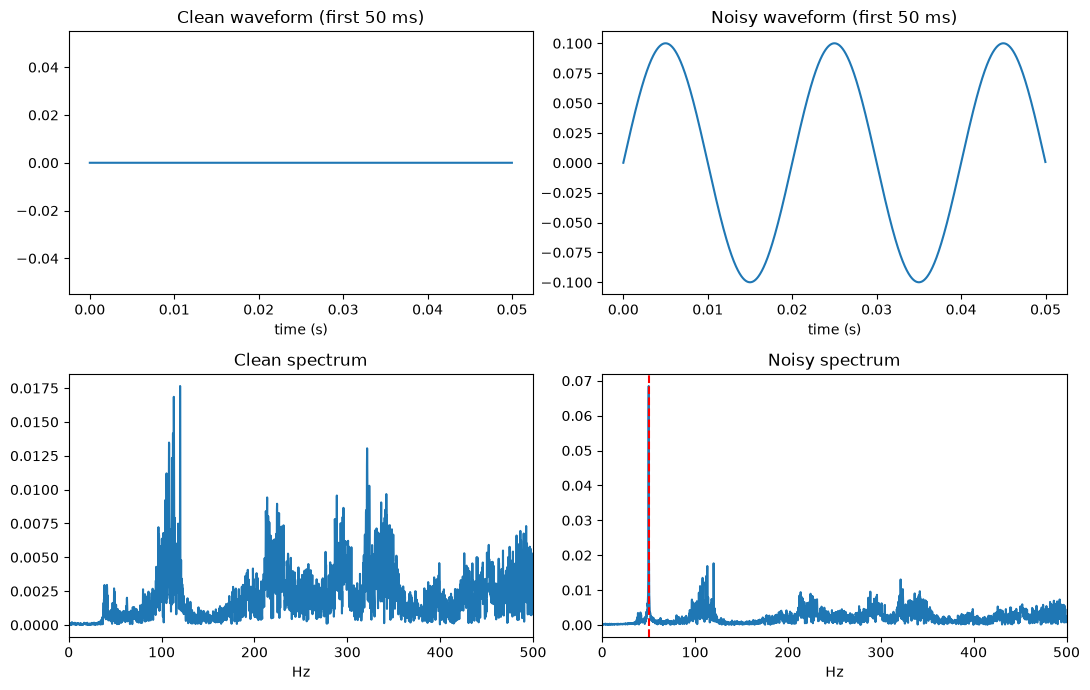

In [18]:
# 1) Load the real recording and build its time axis.
fs, clean_audio = load_audio()
t = np.arange(len(clean_audio))/fs

# 2) Add controlled mains-like interference: 50 Hz, amplitude 0.10.
f_int, A_int = 50, .10
noisy_audio = clean_audio + A_int*np.sin(2*np.pi*f_int*t)

# 3) Calculate clean and noisy amplitude spectra.
f, S_clean = amp_spectrum(clean_audio, fs)
_, S_noisy = amp_spectrum(noisy_audio, fs)

# 4) Search only 40–70 Hz and select the strongest frequency.
band = (f >= 40) & (f <= 70)
f_peak = f[band][np.argmax(S_noisy[band])]
print(f'fs = {fs} Hz | duration = {len(clean_audio)/fs:.2f} s | Nyquist = {fs/2:.0f} Hz')
print(f'Detected interference frequency: {f_peak:.2f} Hz')

# 5) Save the noisy signal as standard 16-bit WAV for Part 4.
wavfile.write('noisy.wav', fs, (noisy_audio/np.max(np.abs(noisy_audio))*32767).astype(np.int16))

# 6) Compare 50 ms of waveform and the spectra up to 500 Hz.
seg = slice(0, min(len(clean_audio), int(.05*fs)))
fig, ax = plt.subplots(2, 2, figsize=(11, 7))
ax[0,0].plot(t[seg], clean_audio[seg]); ax[0,0].set(title='Clean waveform (first 50 ms)', xlabel='time (s)')
ax[0,1].plot(t[seg], noisy_audio[seg]); ax[0,1].set(title='Noisy waveform (first 50 ms)', xlabel='time (s)')
ax[1,0].plot(f, S_clean); ax[1,0].set(title='Clean spectrum', xlim=(0,500), xlabel='Hz')
ax[1,1].plot(f, S_noisy); ax[1,1].axvline(f_int, color='r', ls='--'); ax[1,1].set(title='Noisy spectrum', xlim=(0,500), xlabel='Hz')
plt.tight_layout(); plt.show()

### Part 3 result

The waveform changes only slightly, so the hum may be difficult to see or hear—especially on laptop speakers that reproduce low frequencies poorly. The spectrum clearly detects it near 50 Hz. The measured value is about 50.08 Hz rather than exactly 50 Hz because the FFT evaluates fixed frequency bins. This spreading around nearby bins is called spectral leakage.

## Part 4 — Removing the hum with a notch filter

**Goal:** Remove the detected interference while changing the voice as little as possible.

**Idea in simple words:** A notch filter removes a very narrow band of frequencies. It is the right choice here because we know the unwanted tone is near 50 Hz and want to keep nearly everything else.

$$H(z)=\frac{1-2\cos(\omega_0)z^{-1}+z^{-2}}{1-2r\cos(\omega_0)z^{-1}+r^2z^{-2}}$$

The zeros cancel the frequency $\omega_0$. The poles keep the response close to one outside the notch. The pole radius $r$ is below one, so the IIR filter is stable. A 10 Hz bandwidth keeps the removed region narrow.

**How to read the output:**
- In the first plot, the filtered spectrum should lose its spike near 50 Hz.
- The filter-response plot has a deep, narrow dip at the target frequency.
- The before/after dB values measure the removed tone.
- The voice should remain almost unchanged; that is the desired result.

b = [ 1.00931235 -2.01858132  1.00931235] 
a = [ 1.         -1.99864805  0.99869143]
Pole magnitudes: [0.9993455 0.9993455] | stable: True
Tone before: -23.3 dB | after: -56.1 dB
SNR noisy: 5.8 dB | filtered: 22.8 dB


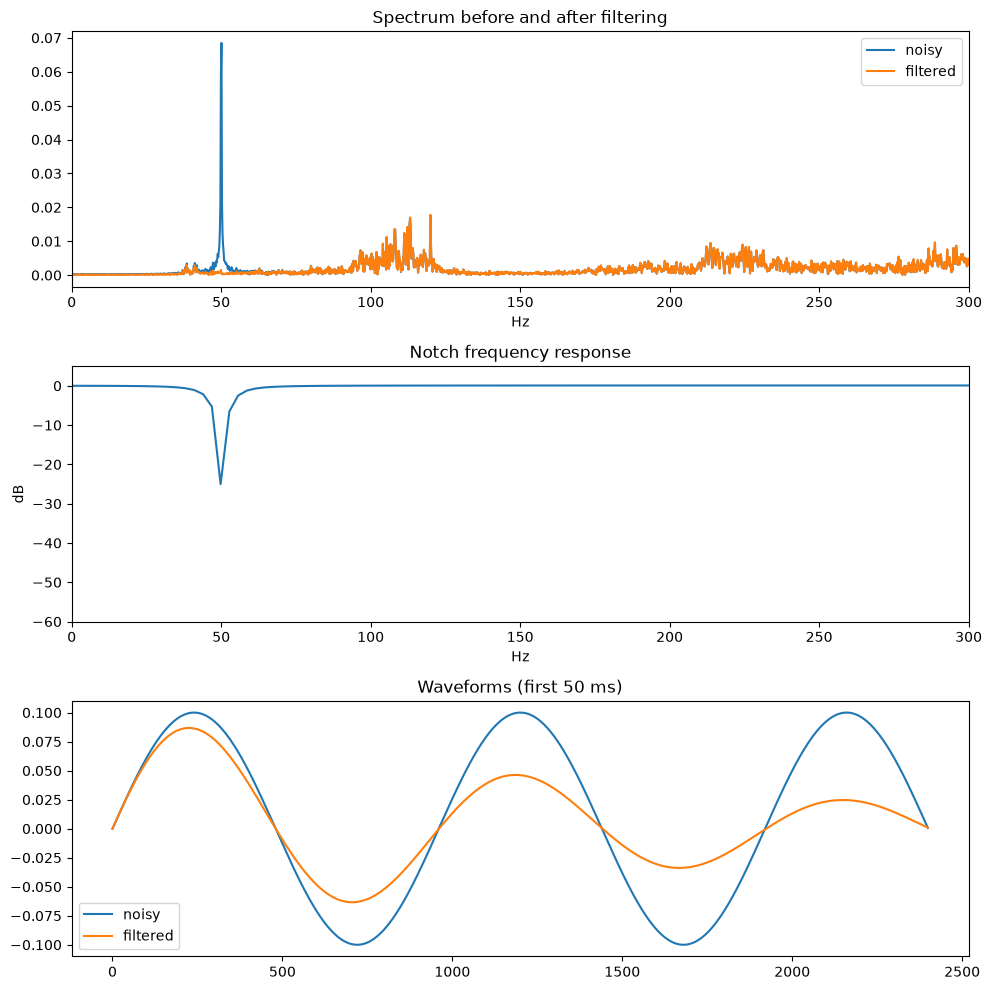

Noisy audio:


Filtered audio:


In [19]:
# 1) Design values: detected centre frequency and 10 Hz bandwidth.
f0, BW = f_peak, 10
r = 1 - np.pi*BW/fs
w0 = 2*np.pi*f0/fs

# 2) Calculate numerator b and denominator a from the notch equation.
b = np.array([1, -2*np.cos(w0), 1.])
a_notch = np.array([1, -2*r*np.cos(w0), r**2])
b *= np.sum(a_notch)/np.sum(b)  # unity DC gain

# 3) All pole magnitudes must be below one for stability.
poles = np.roots(a_notch)
print('b =', b, '\na =', a_notch)
print('Pole magnitudes:', np.abs(poles), '| stable:', np.all(np.abs(poles) < 1))

# 4) Filter the noisy recording and save the result.
filtered = signal.lfilter(b, a_notch, noisy_audio)
wavfile.write('filtered.wav', fs, (filtered/np.max(np.abs(filtered))*32767).astype(np.int16))

# 5) Measure the filtered spectrum and the filter's own response.
_, S_filtered = amp_spectrum(filtered, fs)
wf, Hf = signal.freqz(b, a_notch, worN=8192, fs=fs)

# 6) Helper measurements: tone level near f0 and SNR against clean audio.
def peak_db(S, freq, centre):
    return 20*np.log10(np.max(S[(freq > centre-3) & (freq < centre+3)]) + 1e-12)
def snr_db(ref, test):
    return 10*np.log10(np.sum(ref**2)/np.sum((ref-test)**2))
print(f'Tone before: {peak_db(S_noisy,f,f0):.1f} dB | after: {peak_db(S_filtered,f,f0):.1f} dB')
print(f'SNR noisy: {snr_db(clean_audio,noisy_audio):.1f} dB | filtered: {snr_db(clean_audio,filtered):.1f} dB')

# 7) Compare spectra, filter response, waveforms, and audio playback.
fig, ax = plt.subplots(3, 1, figsize=(10, 10))
ax[0].plot(f,S_noisy,label='noisy'); ax[0].plot(f,S_filtered,label='filtered'); ax[0].legend(); ax[0].set(xlim=(0,300), title='Spectrum before and after filtering', xlabel='Hz')
ax[1].plot(wf,20*np.log10(np.abs(Hf)+1e-12)); ax[1].set(xlim=(0,300), ylim=(-60,5), title='Notch frequency response', xlabel='Hz', ylabel='dB')
ax[2].plot(noisy_audio[:int(.05*fs)],label='noisy'); ax[2].plot(filtered[:int(.05*fs)],label='filtered'); ax[2].legend(); ax[2].set_title('Waveforms (first 50 ms)')
plt.tight_layout(); plt.show()
print('Noisy audio:'); display(Audio(noisy_audio, rate=fs))
print('Filtered audio:'); display(Audio(filtered, rate=fs))

### Part 4 result

The detected tone falls from about **−23.3 dB to −56.1 dB**, a reduction of roughly 33 dB. SNR improves from about **5.8 dB to 22.8 dB**. `filtered.wav` therefore sounds very similar to the original voice—the filter is supposed to remove only a narrow hum, not alter the speaker. A small amount of genuine audio near 50 Hz is also removed, and a short transient can occur at the beginning.

## Part 5 — 2D Fourier transform and image filtering

**Goal:** View the image in the frequency domain and use ideal circular masks to separate smooth content from edges and fine detail.

**Idea in simple words:** Images also contain frequencies. Slow brightness changes are low spatial frequencies, while sharp edges and small textures are high spatial frequencies. `fft2` calculates the 2D spectrum and `fftshift` moves zero frequency to the centre.

An ideal low-pass mask keeps a circle around the centre, producing blur. An ideal high-pass mask removes that circle and keeps frequencies farther away, revealing edges. The cutoff $D_0$ is the radius of the circle.

**How to read the output:**
- The bright spectrum centre contains most of the image's smooth information.
- A smaller low-pass cutoff means stronger blur.
- A high-pass image emphasizes the leaf outline, veins, and texture.
- A sharp ideal mask may create ripples called ringing.

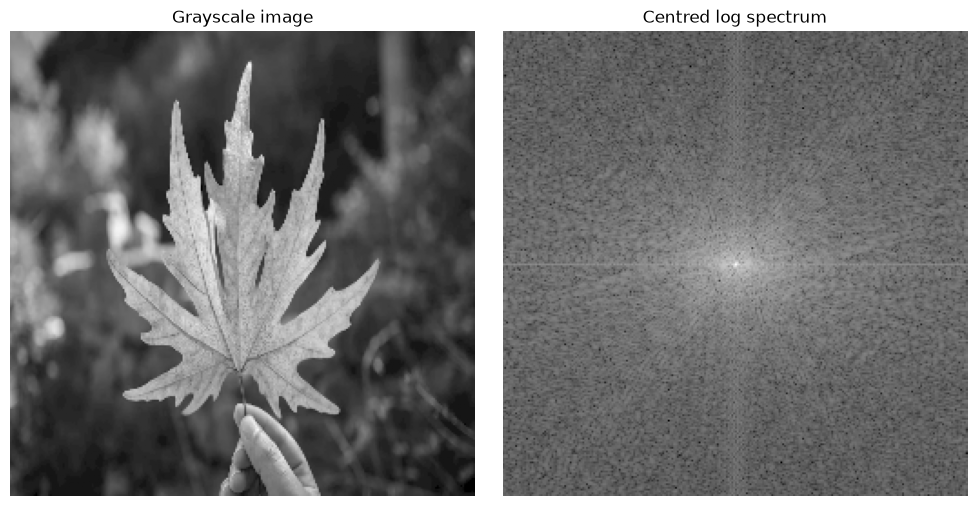

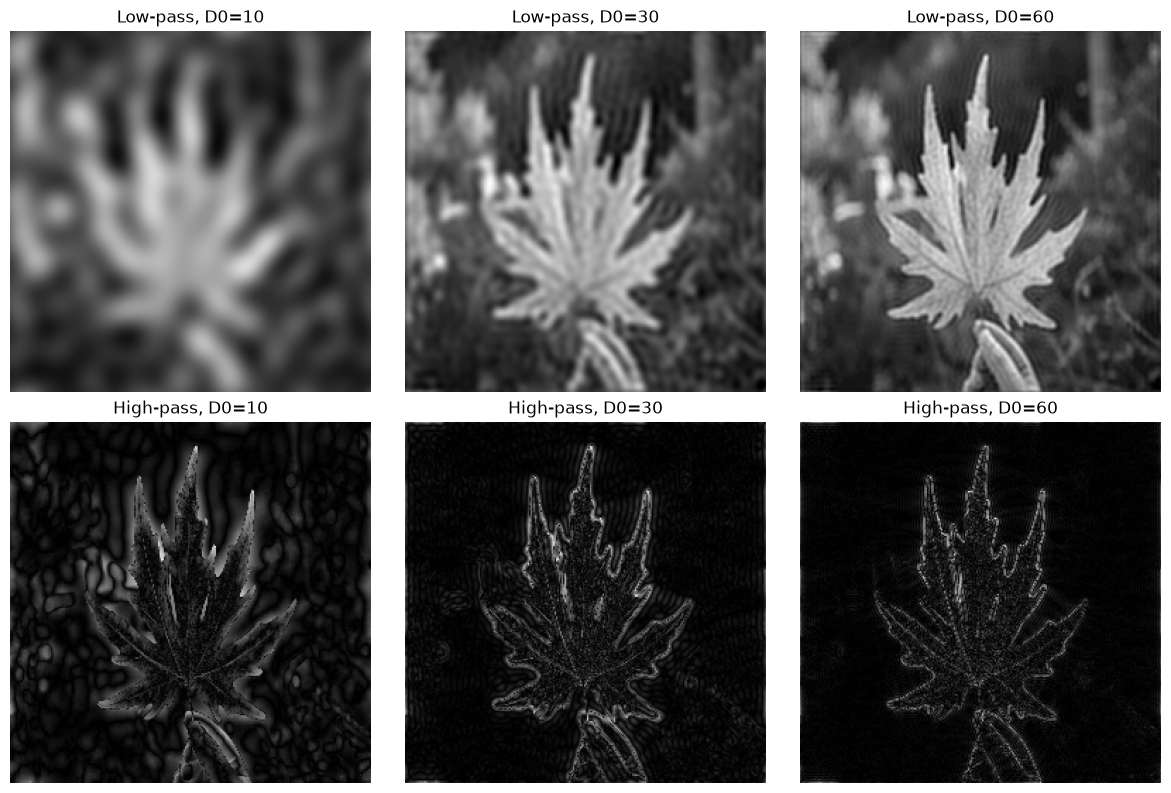

In [20]:
# 1) Load the leaf photo as a 256×256 grayscale image.
img = load_image()
M, Nimg = img.shape

# 2) Calculate the 2D spectrum and move zero frequency to the centre.
F_img = np.fft.fftshift(np.fft.fft2(img))
spectrum_img = np.log1p(np.abs(F_img))

# 3) D stores every spectrum pixel's distance from the centre.
yy, xx = np.ogrid[:M, :Nimg]
D = np.sqrt((yy-M//2)**2 + (xx-Nimg//2)**2)

# Convert a centred frequency spectrum back into a real image.
def to_image(F): return np.real(np.fft.ifft2(np.fft.ifftshift(F)))

# 4) Show the grayscale image beside its log-scaled spectrum.
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(img,cmap='gray',vmin=0,vmax=255); ax[0].set_title('Grayscale image')
ax[1].imshow(spectrum_img,cmap='gray'); ax[1].set_title('Centred log spectrum')
for p in ax: p.axis('off')
plt.tight_layout(); plt.show()

# 5) Try three cutoff radii for ideal low-pass and high-pass masks.
cutoffs = [10,30,60]
fig, ax = plt.subplots(2, len(cutoffs), figsize=(12, 8))
for j, D0 in enumerate(cutoffs):
    ax[0,j].imshow(to_image(F_img*(D <= D0)),cmap='gray',vmin=0,vmax=255); ax[0,j].set_title(f'Low-pass, D0={D0}')
    ax[1,j].imshow(np.abs(to_image(F_img*(D > D0))),cmap='gray'); ax[1,j].set_title(f'High-pass, D0={D0}')
    ax[0,j].axis('off'); ax[1,j].axis('off')
plt.tight_layout(); plt.show()

### Part 5 result

With $D_0=10$, only frequencies close to the centre remain, so the leaf is heavily blurred. Increasing the cutoff to 30 or 60 restores more detail. The high-pass results contain the outline and veins instead of the smooth background. Ringing can appear near strong edges because an ideal mask changes abruptly from zero to one.

## Part 6 — Periodic image-noise removal and evaluation

**Goal:** Add visible stripe noise, locate its two frequency spikes, remove them with a notch mask, and measure the restoration quality.

**Idea in simple words:** A repeating stripe pattern is a 2D sinusoid. In the centred spectrum it creates two bright points placed symmetrically around the centre. Both points must be removed because a real image has symmetric positive and negative frequency components.

The mask places a small black circle over each noise spike. Multiplying the spectrum by this mask removes those frequencies, and the inverse FFT reconstructs the image.

**Quality measures:**
- **MSE:** Average squared pixel error. Lower is better.
- **PSNR:** Image quality in decibels. Higher is better.
- The restored image is compared with the original image, not the noisy image.

Noisy: MSE=788.05, PSNR=19.17 dB
Restored: MSE=4.46, PSNR=41.64 dB


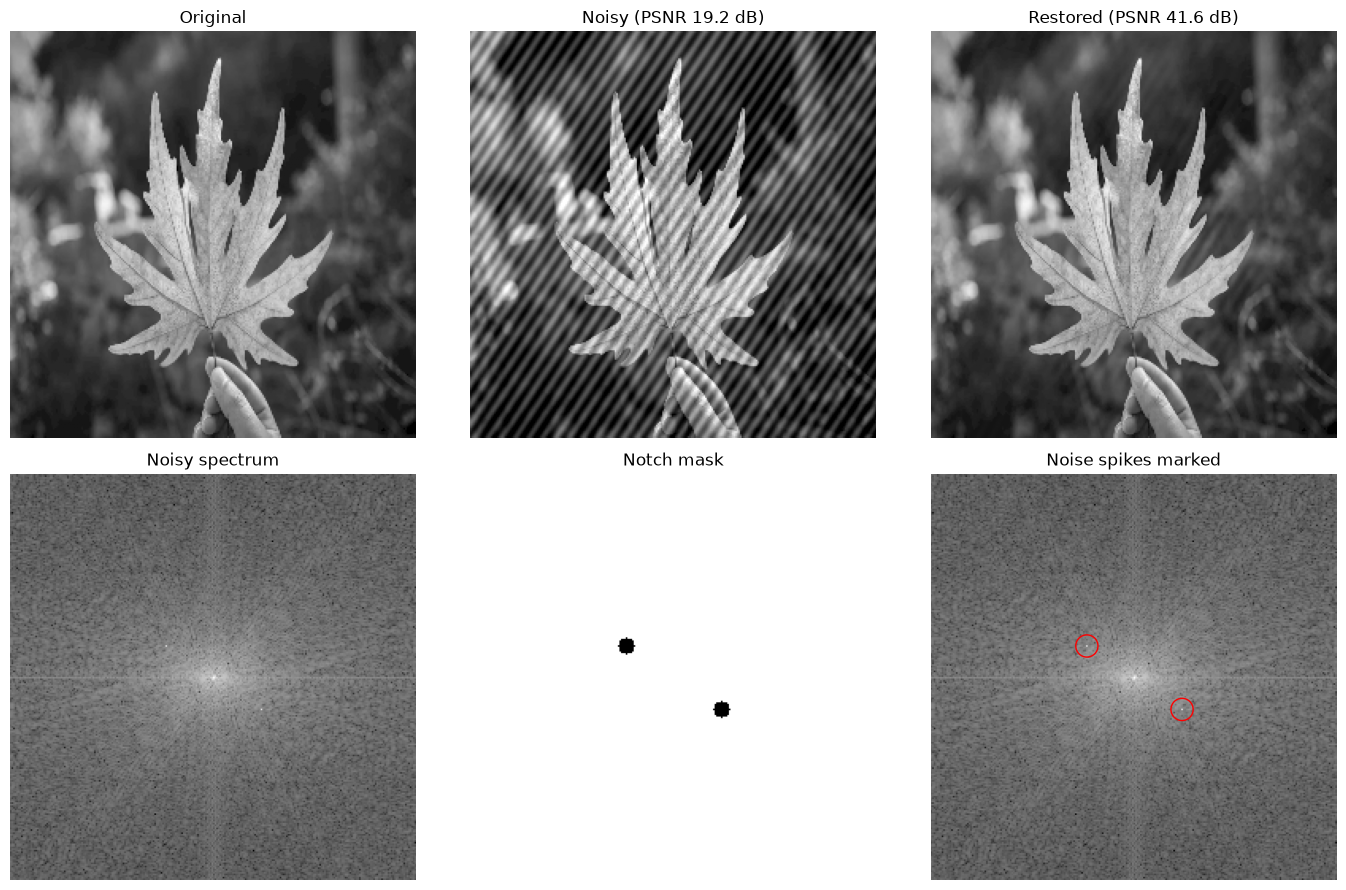

In [21]:
# 1) Create a coordinate grid for every image pixel.
yy, xx = np.mgrid[:M, :Nimg]

# 2) Add a diagonal sinusoidal stripe pattern with known frequencies.
A, u0, v0 = 40, 30, 20
periodic_noise = A*np.sin(2*np.pi*(u0*xx/Nimg + v0*yy/M))
noisy_img = img + periodic_noise

# 3) Transform the noisy image; the stripes become two bright spikes.
F_noisy_img = np.fft.fftshift(np.fft.fft2(noisy_img))
spectrum_noisy_img = np.log1p(np.abs(F_noisy_img))

# 4) Build a mask with a radius-5 hole at each symmetric spike.
R = 5
mask = np.ones((M,Nimg))
spots = []
for s in (1,-1):
    cy, cx = M//2 + s*v0, Nimg//2 + s*u0
    spots.append((cy,cx))
    mask[(yy-cy)**2 + (xx-cx)**2 <= R**2] = 0

# 5) Apply the mask and transform back to the spatial domain.
restored = np.real(np.fft.ifft2(np.fft.ifftshift(F_noisy_img*mask)))

# 6) Compare noisy and restored images against the original.
mse_noisy, psnr_noisy = psnr(img,noisy_img)
mse_restored, psnr_restored = psnr(img,restored)
print(f'Noisy: MSE={mse_noisy:.2f}, PSNR={psnr_noisy:.2f} dB')
print(f'Restored: MSE={mse_restored:.2f}, PSNR={psnr_restored:.2f} dB')

# 7) Display the images, noisy spectrum, mask, and marked spikes.
fig, ax = plt.subplots(2,3,figsize=(14,9))
ax[0,0].imshow(img,cmap='gray',vmin=0,vmax=255); ax[0,0].set_title('Original')
ax[0,1].imshow(np.clip(noisy_img,0,255),cmap='gray',vmin=0,vmax=255); ax[0,1].set_title(f'Noisy (PSNR {psnr_noisy:.1f} dB)')
ax[0,2].imshow(np.clip(restored,0,255),cmap='gray',vmin=0,vmax=255); ax[0,2].set_title(f'Restored (PSNR {psnr_restored:.1f} dB)')
ax[1,0].imshow(spectrum_noisy_img,cmap='gray'); ax[1,0].set_title('Noisy spectrum')
ax[1,1].imshow(mask,cmap='gray'); ax[1,1].set_title('Notch mask')
ax[1,2].imshow(spectrum_noisy_img,cmap='gray'); ax[1,2].set_title('Noise spikes marked')
for cy,cx in spots: ax[1,2].add_patch(plt.Circle((cx,cy),R+2,fill=False,color='r'))
for p in ax.ravel(): p.axis('off')
plt.tight_layout(); plt.show()

### Part 6 result

The periodic noise creates two bright symmetric points in the spectrum. After notching both points, the stripes almost disappear. MSE falls from about **788.05 to 4.46**, while PSNR rises from about **19.17 dB to 41.64 dB**. The result is not perfectly identical to the original because each notch also removes a small amount of real image information. A larger notch removes more noise but risks losing more detail.

## Final summary and discussion guide

| Part | One-sentence explanation | Important result |
|---|---|---|
| 1 | The DTFT changes a time signal into magnitude and phase versus frequency. | Manual DTFT agrees with the FFT. |
| 2 | Convolution describes the output of an LTI system. | FFT convolution needs zero-padding to avoid wrap-around. |
| 3 | A repeated tone is easier to find in a spectrum than in a waveform. | The added interference is detected near 50 Hz. |
| 4 | A notch filter removes a narrow frequency band and keeps the rest. | The 50 Hz tone falls by about 33 dB. |
| 5 | Low image frequencies are smooth areas; high frequencies are edges. | Low-pass blurs and high-pass reveals detail. |
| 6 | Periodic stripes create two symmetric spectral spikes. | PSNR improves from about 19.17 dB to 41.64 dB. |

### Short glossary

- **Sample:** One measured value of a digital signal.
- **Frequency spectrum:** A view of how strongly each frequency appears.
- **Magnitude:** Strength of a frequency component.
- **Phase:** Relative timing or shift of a frequency component.
- **LTI system:** A linear, time-invariant system described by convolution.
- **FIR:** A filter without output feedback.
- **IIR:** A filter with feedback; it can have an infinitely long response.
- **Notch filter:** A filter that removes a narrow frequency band.
- **MSE:** Average squared difference from the reference; lower is better.
- **PSNR:** Image-quality measurement in dB; higher is better.

### Files produced

- `noisy.wav`: the recording after adding 50 Hz interference.
- `filtered.wav`: the notch-filtered recording used for the final audio comparison.